Template: AECC1.jpg, 5 images to align

AAAA1.jpg: 2414 keypoints (template: 14272)
   good matches: 51,  RANSAC inliers: 18
   H =
 [[ 1.2005000e+00 -1.1096000e+00  1.0468395e+03]
 [ 6.4290000e-01  9.5130000e-01 -3.1815520e+02]
 [ 0.0000000e+00 -1.0000000e-04  1.0000000e+00]]


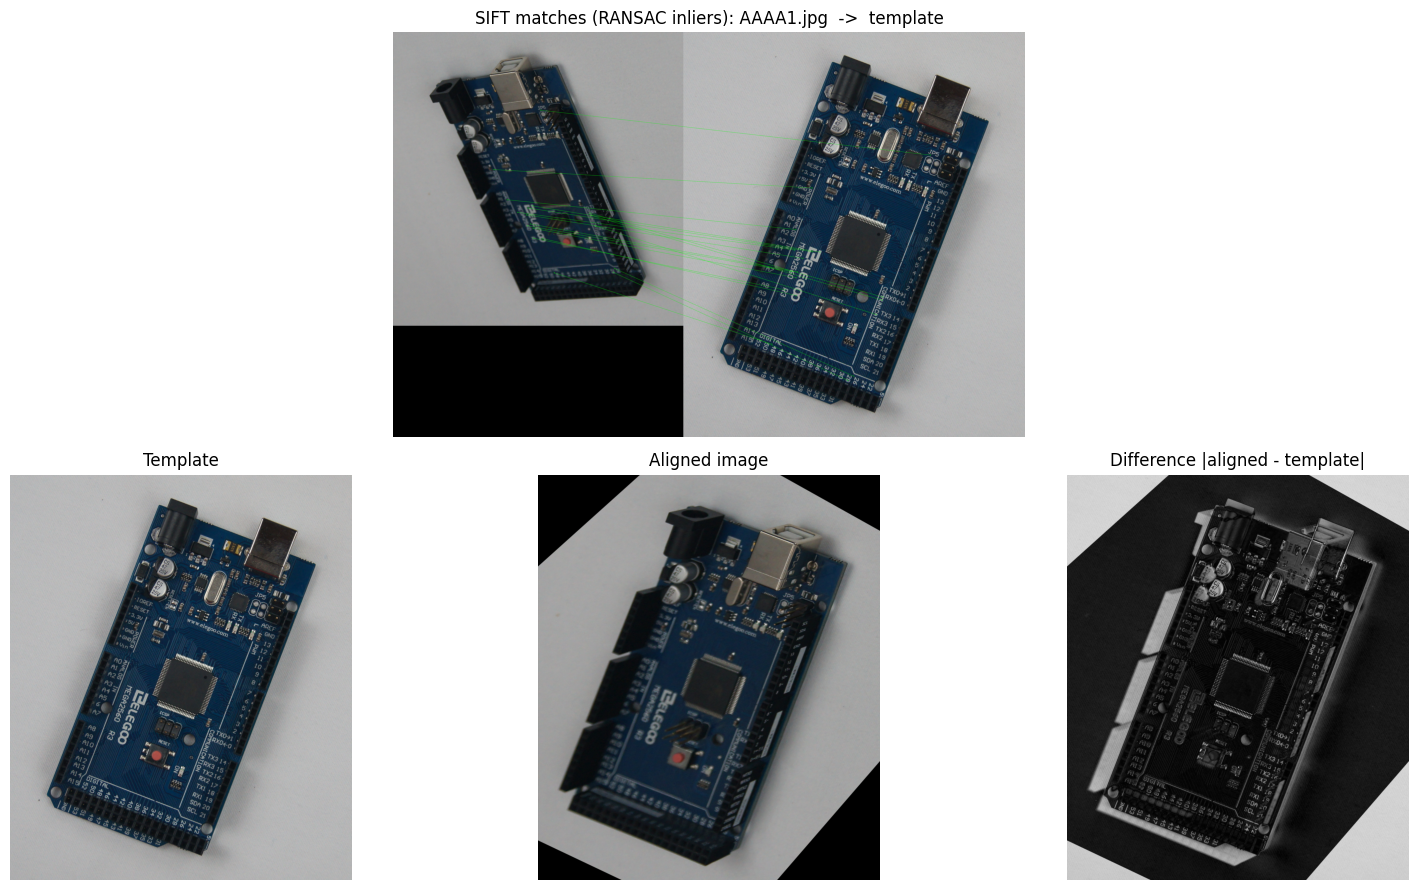

ADAD1.jpg: 8486 keypoints (template: 14272)
   good matches: 369,  RANSAC inliers: 194
   H =
 [[ 1.226400e+00 -1.610000e-02 -5.789270e+01]
 [ 1.391000e-01  1.049700e+00 -1.442432e+02]
 [ 1.000000e-04  0.000000e+00  1.000000e+00]]


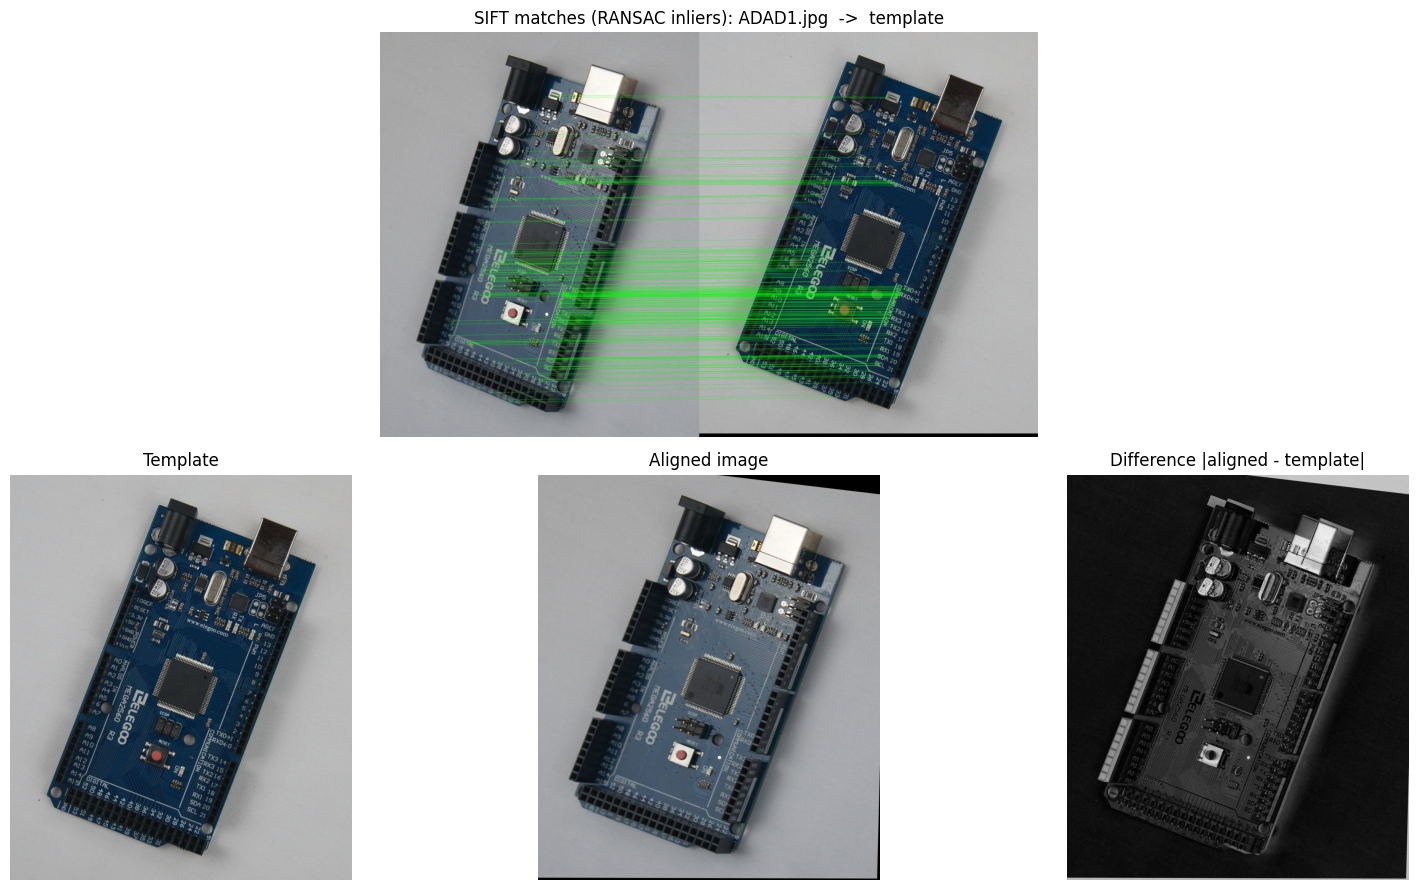

AECC2.jpg: 12315 keypoints (template: 14272)
   good matches: 4322,  RANSAC inliers: 3847
   H =
 [[ 1.00060e+00 -1.50000e-02  3.21100e+01]
 [ 1.66000e-02  1.00000e+00 -1.81596e+01]
 [ 0.00000e+00  0.00000e+00  1.00000e+00]]


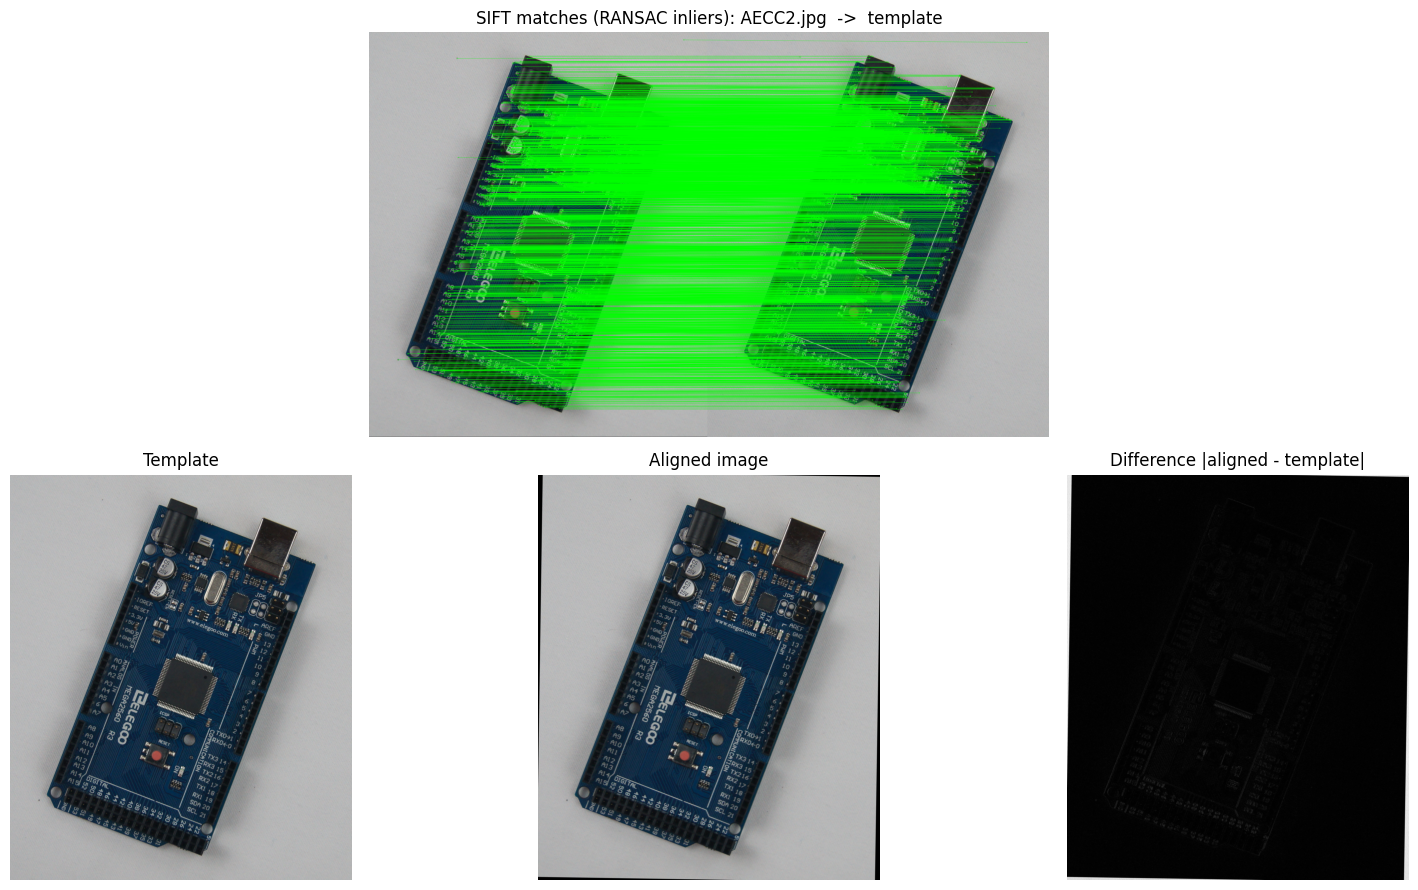

AECC3.jpg: 15198 keypoints (template: 14272)
   good matches: 5629,  RANSAC inliers: 5006
   H =
 [[ 9.99600e-01 -1.00000e-02  2.24371e+01]
 [ 1.04000e-02  9.99200e-01 -1.13615e+01]
 [ 0.00000e+00  0.00000e+00  1.00000e+00]]


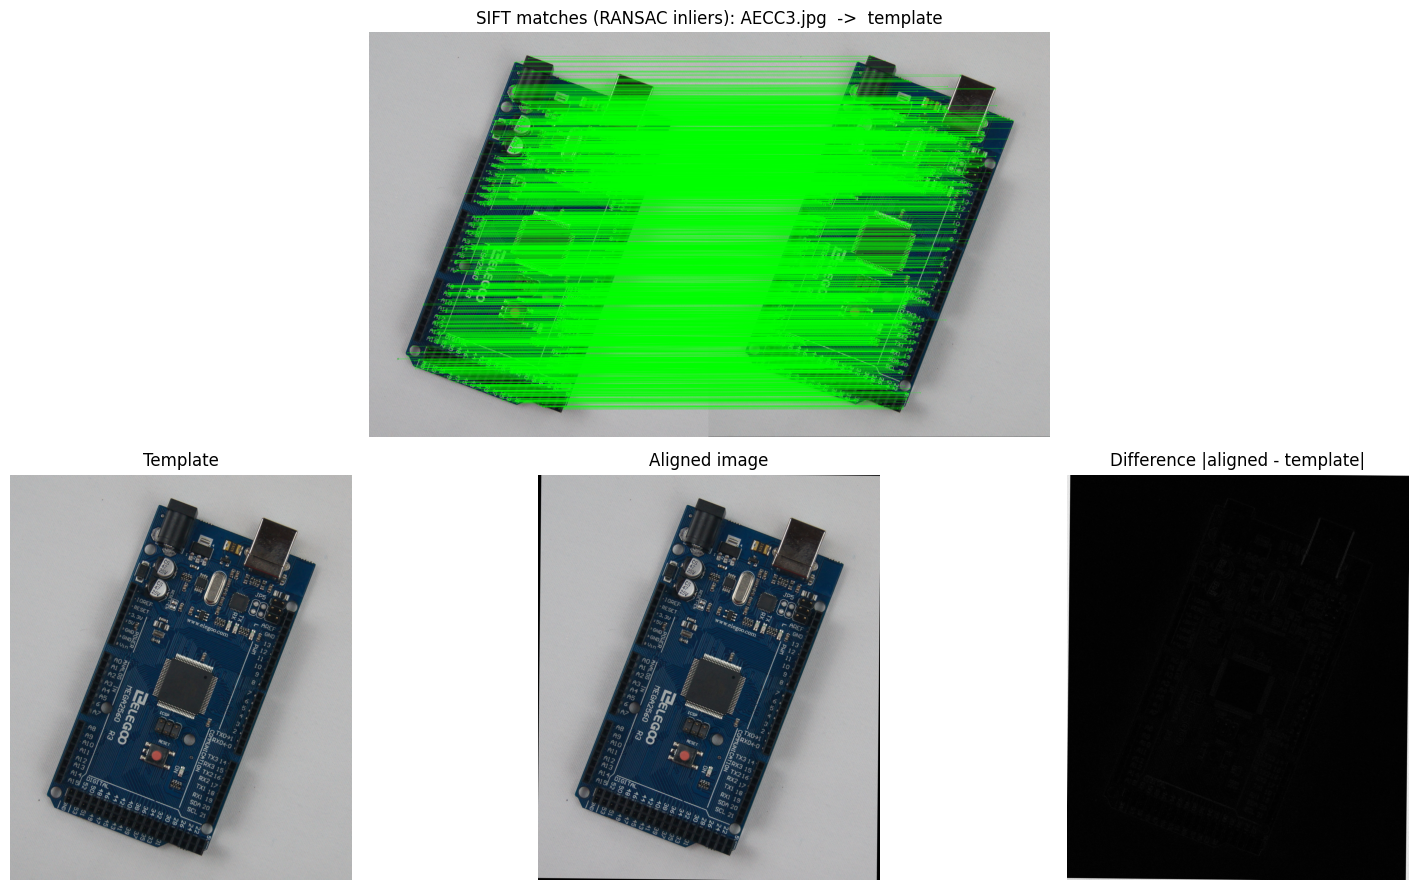

AECC4.jpg: 11610 keypoints (template: 14272)
   good matches: 3830,  RANSAC inliers: 3402
   H =
 [[ 9.99400e-01 -1.40000e-02  3.15510e+01]
 [ 1.39000e-02  9.99000e-01 -1.39158e+01]
 [ 0.00000e+00  0.00000e+00  1.00000e+00]]


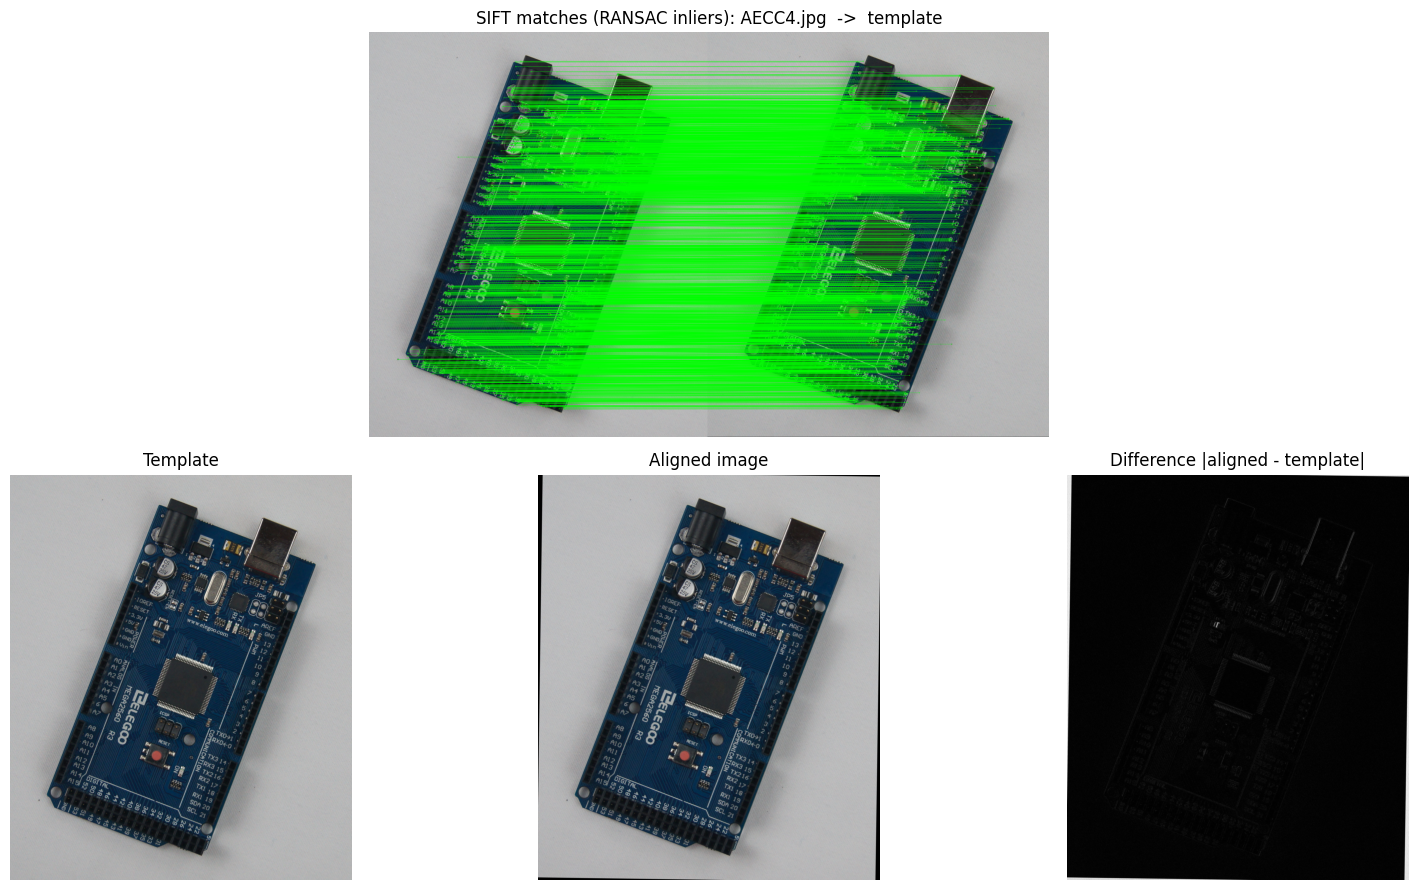

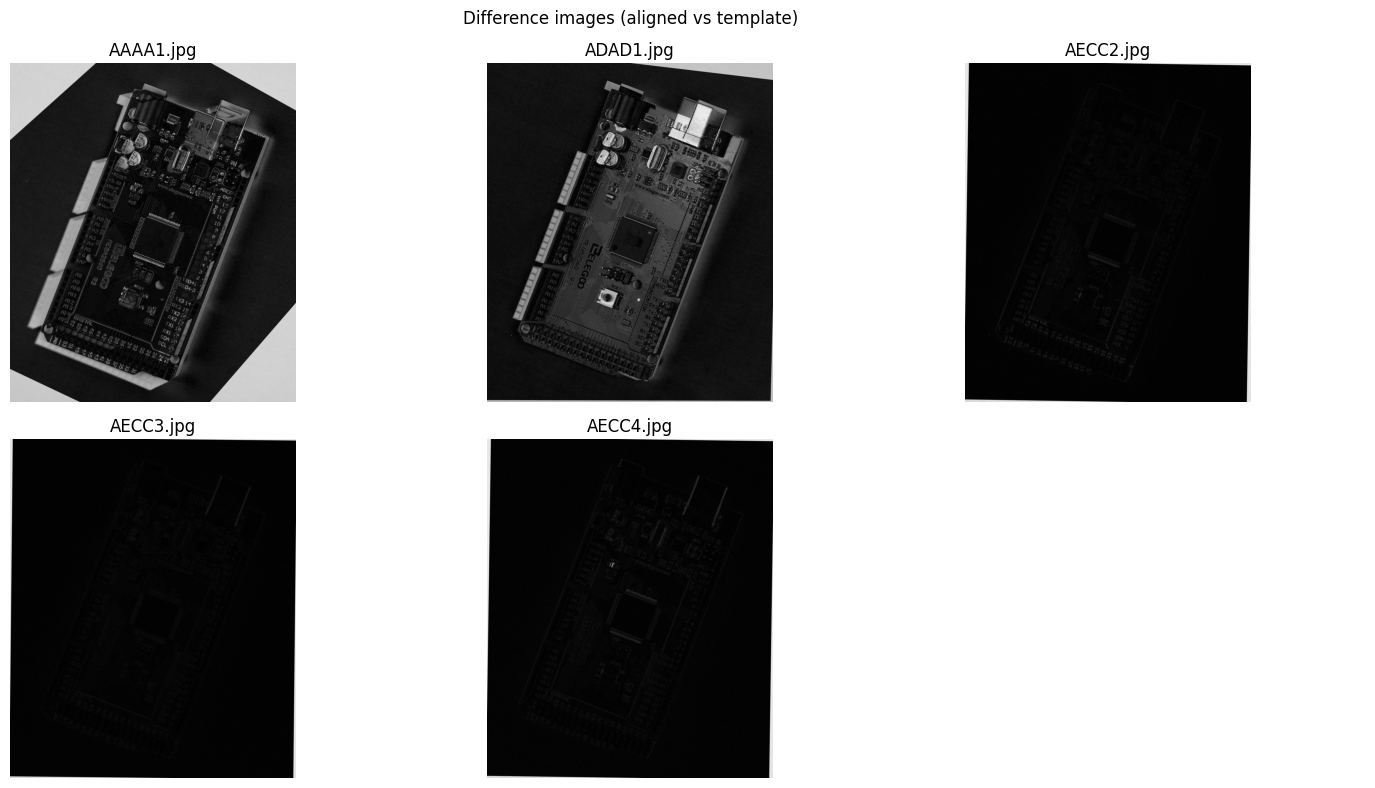

In [ ]:
# Q 4
import glob
import os
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt


In [ ]:

IMG_DIR = 'a2images/pcbs'
TEMPLATE_NAME = 'AECC1.jpg'
RATIO = 0.75           
RANSAC_THRESH = 5.0     
MIN_MATCHES = 10
OUT_DIR = 'q4_results'


In [ ]:
def load_images():
    template = cv.imread(os.path.join(IMG_DIR, TEMPLATE_NAME))
    if template is None:
        raise FileNotFoundError(os.path.join(IMG_DIR, TEMPLATE_NAME))
    paths = []
    for ext in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG'):
        paths += glob.glob(os.path.join(IMG_DIR, ext))
    paths = sorted(p for p in set(paths) if os.path.basename(p) != TEMPLATE_NAME)
    return template, paths



def detect_sift(img_gray):
    sift = cv.SIFT_create()
    return sift.detectAndCompute(img_gray, None)


def match_and_find_homography(kp_img, des_img, kp_tpl, des_tpl):
    bf = cv.BFMatcher(cv.NORM_L2)                       # (no crossCheck: we use the ratio test)
    knn = bf.knnMatch(des_img, des_tpl, k=2)
    good = [m for m, n in (p for p in knn if len(p) == 2) if m.distance < RATIO * n.distance]
    if len(good) < MIN_MATCHES:
        return None, None, good
    src = np.float32([kp_img[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)   # image
    dst = np.float32([kp_tpl[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)   # template
    H, mask = cv.findHomography(src, dst, cv.RANSAC, RANSAC_THRESH)
    return H, mask.ravel().astype(bool), good


def process(template, img_path):
    img = cv.imread(img_path)
    t_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)
    i_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    kp_t, des_t = detect_sift(t_gray)
    kp_i, des_i = detect_sift(i_gray)
    print(f'{os.path.basename(img_path)}: {len(kp_i)} keypoints (template: {len(kp_t)})')

    H, inl_mask, good = match_and_find_homography(kp_i, des_i, kp_t, des_t)
    if H is None:
        print('   not enough matches, skipped')
        return None
    print(f'   good matches: {len(good)},  RANSAC inliers: {int(inl_mask.sum())}')
    print('   H =\n', np.round(H, 4))

    # draw the RANSAC inlier matches (image on the left, template on the right)
    vis = cv.drawMatches(img, kp_i, template, kp_t, good, None,
                         matchesMask=inl_mask.astype(int).tolist(),
                         matchColor=(0, 255, 0), singlePointColor=None,
                         flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

    h, w = template.shape[:2]
    aligned = cv.warpPerspective(img, H, (w, h))
    diff = cv.absdiff(aligned, template)
    diff_gray = cv.cvtColor(diff, cv.COLOR_BGR2GRAY)
    return dict(name=os.path.basename(img_path), img=img, matches=vis,
                aligned=aligned, diff=diff, diff_gray=diff_gray, H=H)



In [ ]:

def show(template, res):
    fig = plt.figure(figsize=(16, 9))
    ax = fig.add_subplot(2, 1, 1)
    ax.imshow(cv.cvtColor(res['matches'], cv.COLOR_BGR2RGB)); ax.axis('off')
    ax.set_title(f"SIFT matches (RANSAC inliers): {res['name']}  ->  template")
    for i, (im, title, cmap) in enumerate([
            (cv.cvtColor(template, cv.COLOR_BGR2RGB), 'Template', None),
            (cv.cvtColor(res['aligned'], cv.COLOR_BGR2RGB), 'Aligned image', None),
            (res['diff_gray'], 'Difference |aligned - template|', 'gray')]):
        a = fig.add_subplot(2, 3, 4 + i)
        a.imshow(im, cmap=cmap); a.set_title(title); a.axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, f"{os.path.splitext(res['name'])[0]}_result.png"), dpi=130)
    plt.show()



In [ ]:

def main():
    os.makedirs(OUT_DIR, exist_ok=True)
    template, paths = load_images()
    print(f'Template: {TEMPLATE_NAME}, {len(paths)} images to align\n')

    results = []
    for p in paths:
        res = process(template, p)
        if res is not None:
            show(template, res)
            results.append(res)

    # (d) all difference images in one figure
    if results:
        n = len(results)
        cols = min(3, n)
        rows = int(np.ceil(n / cols))
        fig, axs = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows), squeeze=False)
        for a in axs.ravel():
            a.axis('off')
        for a, r in zip(axs.ravel(), results):
            a.imshow(r['diff_gray'], cmap='gray'); a.set_title(r['name'])
        plt.suptitle('Difference images (aligned vs template)')
        plt.tight_layout()
        plt.savefig(os.path.join(OUT_DIR, 'all_differences.png'), dpi=130)
        plt.show()



if __name__ == '__main__':
    main()